# Getting to know the games
I wanted to understand what these basketball records could tell me before trying to predict anything. These explorations use development seasons through 2022–23; 2023–24 stays reserved for the final check.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'Data').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
TABLES = ROOT / 'artifacts/tables'
pd.set_option('display.max_columns', 12)

## What does one row mean?
There are two offensive team rows per game. The player file also includes rostered players who did not play. Opponent offense supplies team defense; overlapping player on-court totals cannot be added into team totals.

In [2]:
from src.data import load_data, validate_data
team, player = load_data()
games, audit, contradictions, mismatches = validate_data(team, player)
display(pd.DataFrame({'rows':[len(team),len(player)],'columns':[len(team.columns),len(player.columns)]},index=['Team file','Player file']))
display(contradictions[['nbagameid','player_name','missed','seconds']])

,rows,columns
Team file,27144,41
Player file,434797,59


,nbagameid,player_name,missed,seconds
56613,40500131,Ira Newble,1,0.3
85873,40400126,Justin Reed,1,0.5
116126,41000162,Armon Johnson,1,0.3
246142,22000158,R.J. Hampton,1,3.3


The keys are unique, and player points reconcile with team totals. Four names are missing but their identifiers are valid. Four missed flags conflict with positive playing time, so participation takes precedence. Thirty-four team-game clocks total fewer than 239 player-minutes; I use recorded minute shares and omit clock-derived pace.

## How much does home court show up?

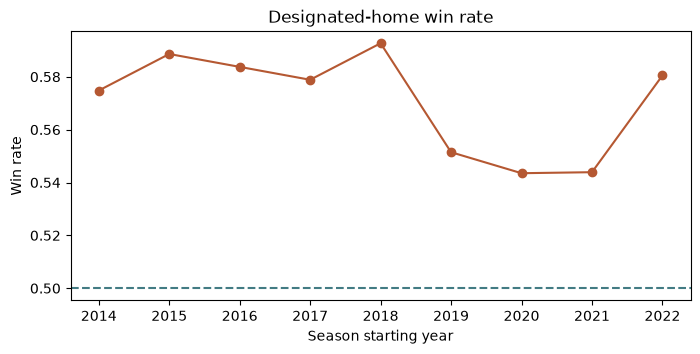

Development home-win rate: 0.5715880547027631


In [3]:
regular = games[(games.gametype == 2) & (games.season < 2023)]
home = regular[regular.off_home == 1].groupby('season').off_win.mean()
ax = home.plot(marker='o',color='#b55832',figsize=(8,3.5),title='Designated-home win rate')
ax.axhline(.5,linestyle='--',color='#427b83')
ax.set(xlabel='Season starting year',ylabel='Win rate')
plt.show()
print('Development home-win rate:',regular.loc[regular.off_home.eq(1),'off_win'].mean())

Home teams won 57.2% of development games, but the advantage varied. The data identify designated hosts, not neutral venues. This supports a useful baseline, not a causal estimate of arena advantage.

## Does recent form tell a different story?

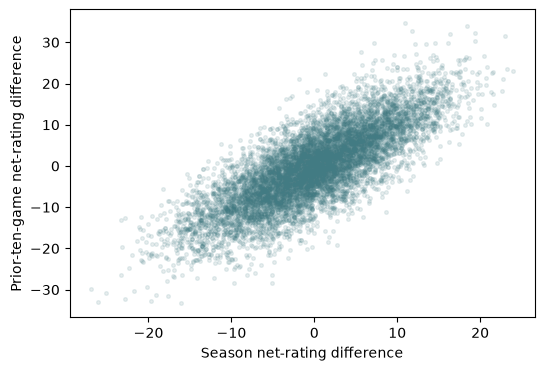

Correlation: 0.794


In [4]:
matchups = pd.read_csv(TABLES / 'matchups.csv.gz')
dev = matchups[matchups.eligible & (matchups.season < 2023)]
ax = dev.plot.scatter(x='net_rating_diff',y='last10_net_rating_diff',alpha=.12,s=7,color='#427b83',figsize=(6,4))
ax.set(xlabel='Season net-rating difference',ylabel='Prior-ten-game net-rating difference')
plt.show()
print('Correlation:',round(dev.net_rating_diff.corr(dev.last10_net_rating_diff),3))

The correlation is 0.794: recent form often agrees with season strength, with some disagreements. Whether those disagreements help is a question for later-season validation.

## Who carries the minutes?

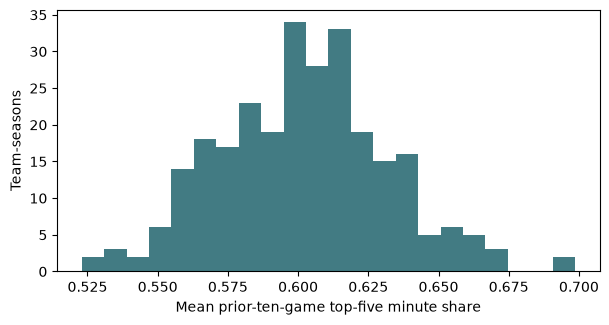

,season,off_team,top5_share,continuity,volatility,participation
107,2017,MIN,0.697,0.894,0.107,0.887
182,2020,BOS,0.566,0.787,0.243,0.740


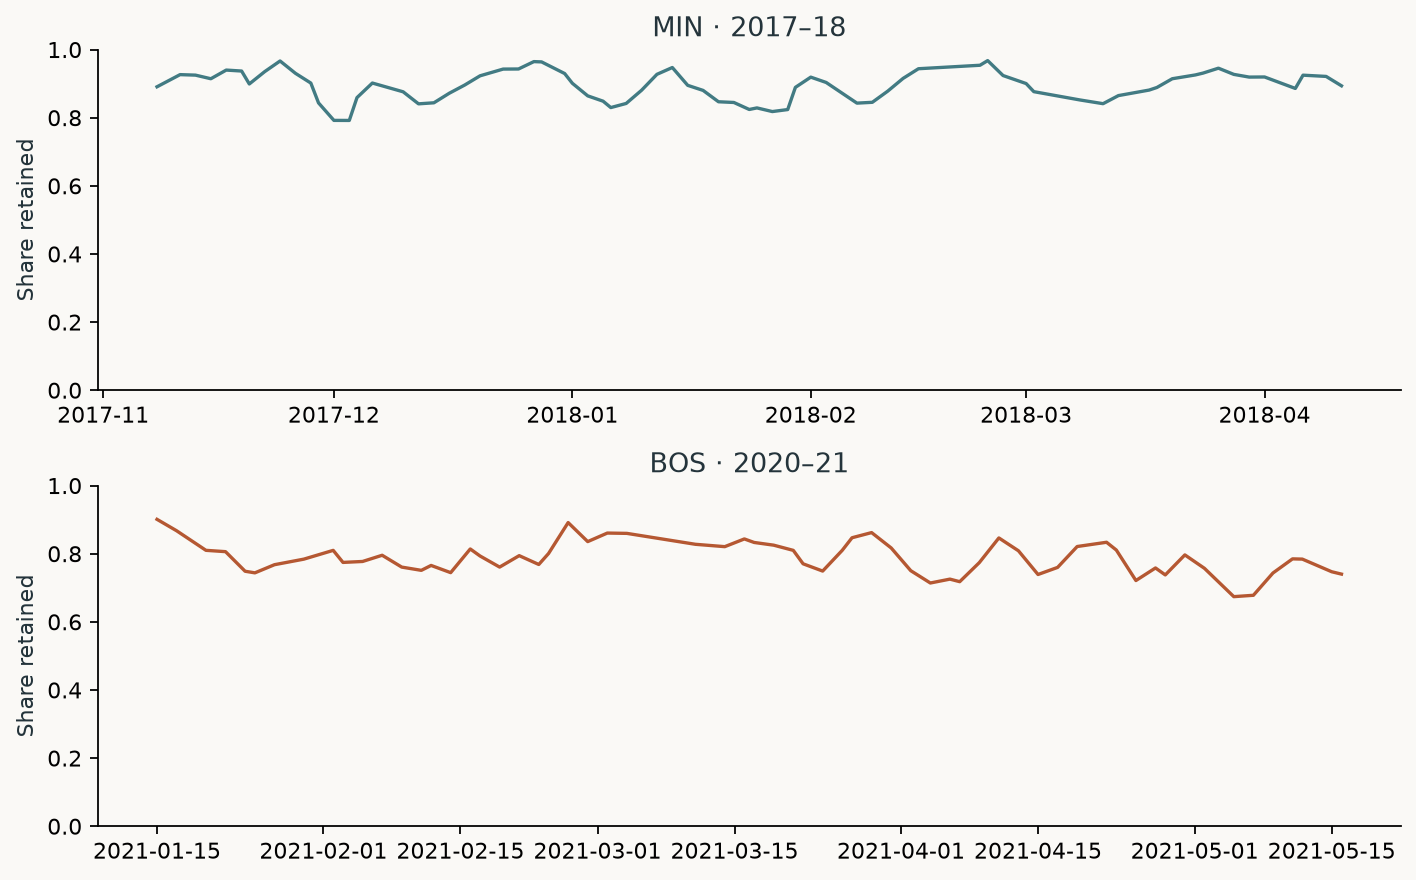

In [5]:
rotations = pd.read_csv(TABLES / 'eda_rotations.csv')
ax = rotations.top5_share.plot.hist(bins=22,color='#427b83',figsize=(7,3.4))
ax.set(xlabel='Mean prior-ten-game top-five minute share',ylabel='Team-seasons')
plt.show()
display(rotations.sort_values('volatility').iloc[[0,-1]].round(3))
display(Image(filename=str(ROOT / 'artifacts/figures/rotation_stories.png')))

The top five account for an average 60.2% of recent minutes across development team-seasons. Minnesota in 2017–18 has the lowest average game-to-game minute-share volatility; Boston in 2020–21 has the highest. These describe the records without attributing changes to injuries or coaching decisions. The variation is a reason to build player histories carefully.